## Model Error Mapping
Assess model output errors spatially.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

In [ ]:
# Load the CSV data
df = pd.read_csv('../combined_results.csv')

In [2]:
df.head()

,site,latitude,longitude,output_years,bias_s00000000_ghec,rmse_s00000000_ghec,mean_snotel_swe,var_snotel_swe,bias_s01011010_gbc,rmse_s01011010_gbc,bias_s01011010_ghec,rmse_s01011010_ghec,bias_s01011010_ghelaps,rmse_s01011010_ghelaps,drmse_s01011010_gbc,drmse_s01011010_ghec,drmse_s01011010_ghelaps,dbias_s01011010_gbc,dbias_s01011010_ghec,dbias_s01011010_ghelaps
0,Forestdale Creek,38.682311,-119.960653,16.0,-95.3,168.5,277.6,150622.6,7.2,63.5,131.3,251.7,55.8,106.6,-105.0,83.2,-61.9,102.5,226.6,151.1
1,Horse Meadow,38.836411,-119.888317,11.2,-22.0,66.2,127.6,38347.5,-8.3,49.7,49.2,110.3,19.7,64.6,-16.5,44.1,-1.6,13.7,71.2,41.7
2,Burnside Lake,38.719328,-119.895194,16.0,-7.2,89.5,196.3,83372.0,34.3,75.5,133.7,254.1,78.0,150.9,-14.0,164.6,61.4,41.5,140.9,85.2
3,Summit Meadow,38.397400,-119.536217,9.2,-9.4,67.5,103.5,25719.7,5.7,31.2,67.9,140.2,38.3,84.2,-36.3,72.7,16.7,15.1,77.3,47.7
4,Carson Pass,38.692667,-120.002128,14.0,-67.7,124.9,233.7,107471.6,-12.9,56.2,87.3,205.2,28.2,84.4,-68.7,80.3,-40.5,54.8,155.0,95.9


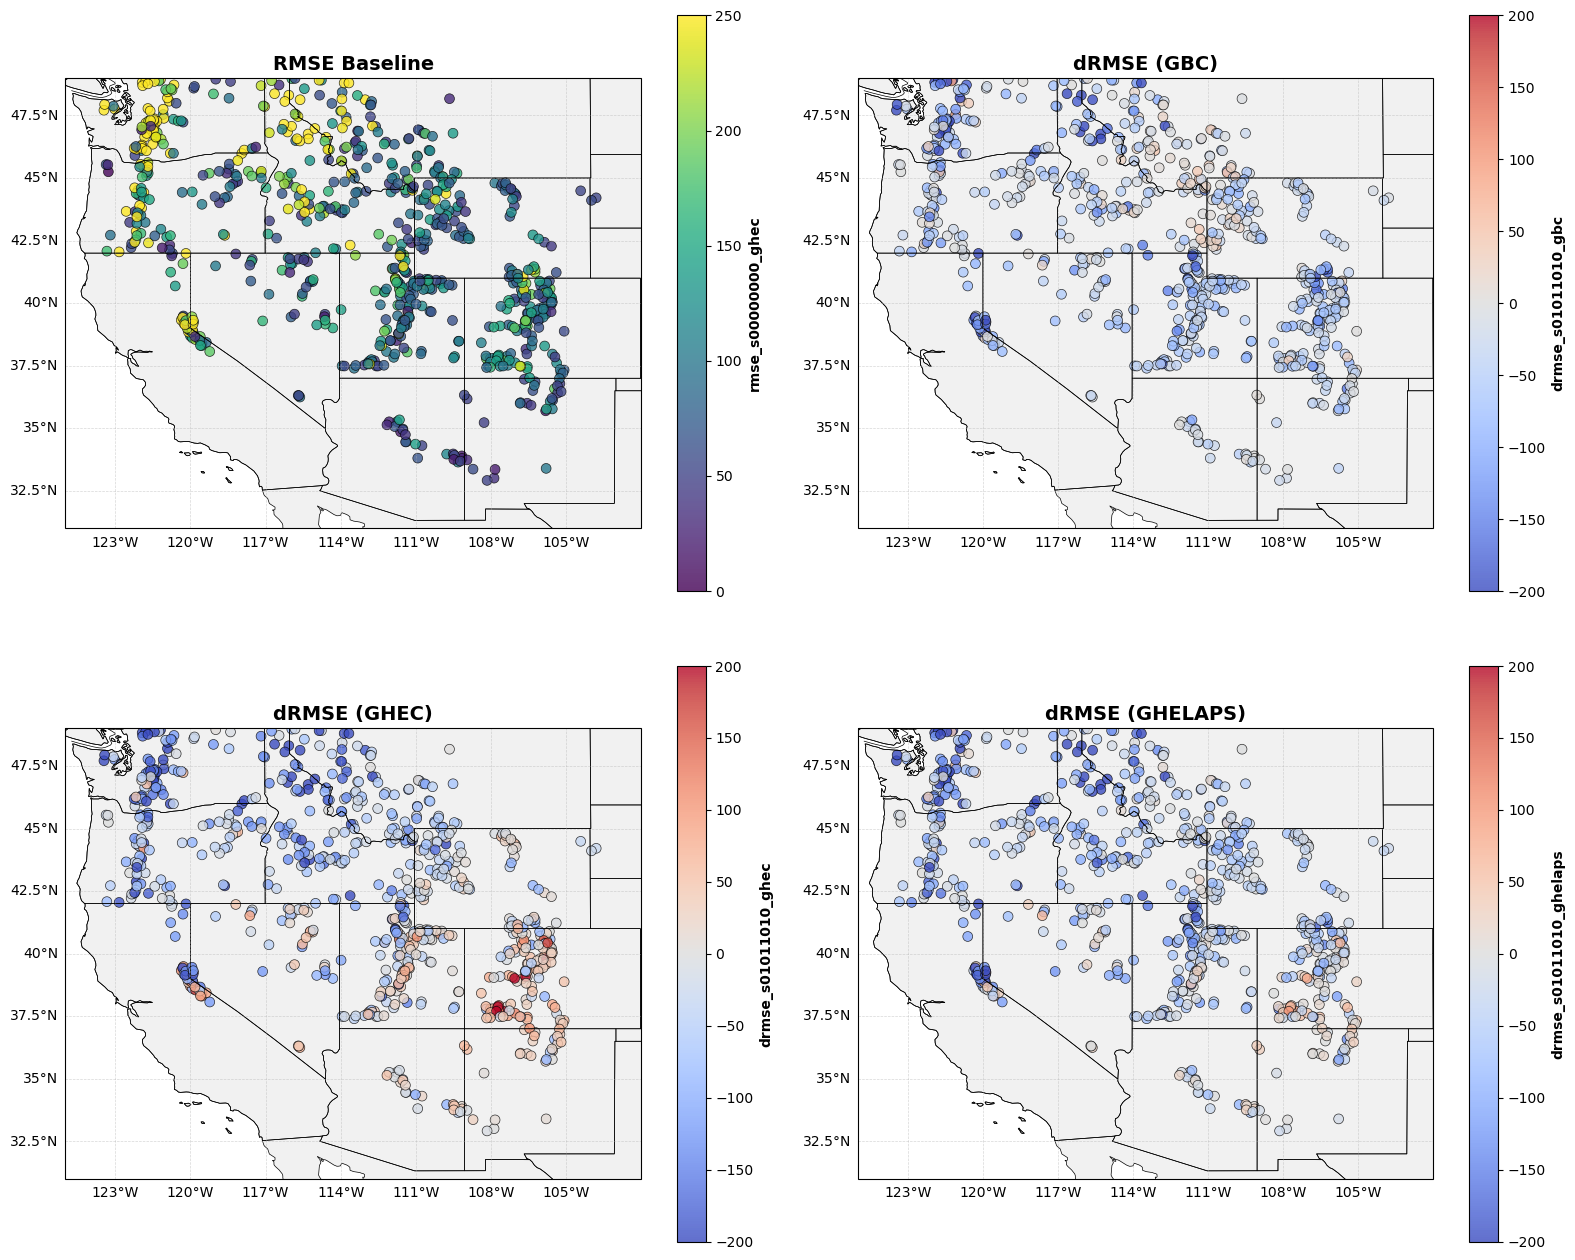

Total data points: 784

Value ranges:
rmse_s00000000_ghec: 3.00 to 1346.80
drmse_s01011010_gbc: -759.00 to 93.50
drmse_s01011010_ghec: -1028.30 to 6959.00
drmse_s01011010_ghelaps: -850.20 to 104.10

Colormap ranges:
Baseline RMSE: 0 to 250
dRMSE plots: -200 to 200


In [12]:
# Create figure with 2x2 grid of subplots
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['rmse_s00000000_ghec', 'drmse_s01011010_gbc', 'drmse_s01011010_ghec', 'drmse_s01011010_ghelaps']
titles = ['RMSE Baseline', 'dRMSE (GBC)', 'dRMSE (GHEC)', 'dRMSE (GHELAPS)']

# Set color scale limits
vmax_baseline = 250  # Different scale for baseline RMSE
vmin_baseline = 0
vmax_drmse = 200     # Symmetric scale for drmse plots
vmin_drmse = -200

# Create four subplots in 2x2 grid
for pos, column in enumerate(zip(columns, titles), 1):
    column, title = column  # Unpack from zip
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Use different color scales for baseline vs drmse
    if pos == 1:  # Baseline RMSE
        vmin, vmax = vmin_baseline, vmax_baseline
        cmap = 'viridis'
    else:  # drmse plots
        vmin, vmax = vmin_drmse, vmax_drmse
        cmap = 'coolwarm'
    
    # Plot the data points
    scatter = ax.scatter(df['longitude'], df['latitude'],
                         c=df[column],
                         s=50,
                         alpha=0.8,
                         cmap=cmap,
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {df[column].min():.2f} to {df[column].max():.2f}")
print(f"\nColormap ranges:")
print(f"Baseline RMSE: {vmin_baseline} to {vmax_baseline}")
print(f"dRMSE plots: {vmin_drmse} to {vmax_drmse}")

### Normalized RMSE Calculation
In order to compare RMSE across sites it needs to be normalized. Following Krinner et al. (2018) we normalize RMSE by the standard deviation of the observations at each site.

In [14]:
df['nrmse_s00000000_ghec'] = df['rmse_s00000000_ghec'] / np.sqrt(df['var_snotel_swe'])
df['nrmse_s01011010_ghec'] = df['rmse_s01011010_ghec'] / np.sqrt(df['var_snotel_swe'])
df['nrmse_s01011010_ghelaps'] = df['rmse_s01011010_ghelaps'] / np.sqrt(df['var_snotel_swe'])
df['nrmse_s01011010_gbc'] = df['rmse_s01011010_gbc'] / np.sqrt(df['var_snotel_swe'])

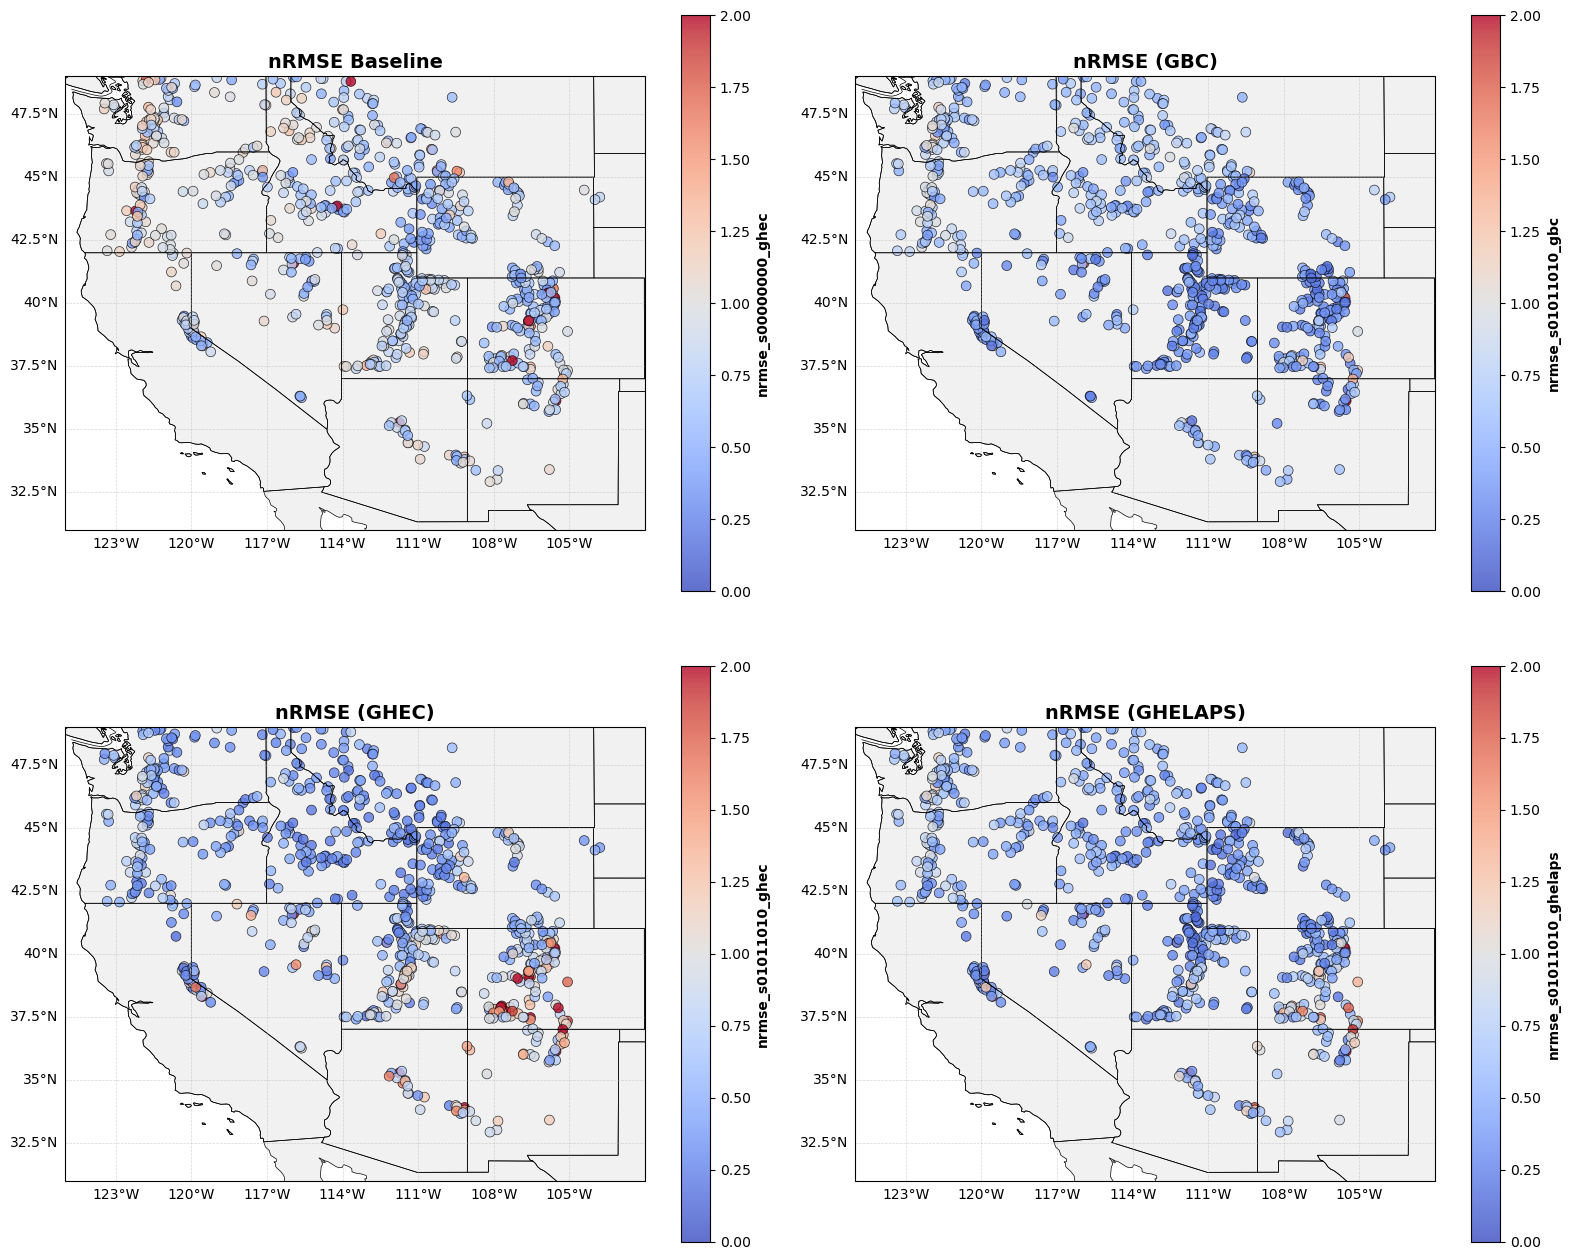

Total data points: 784

Value ranges:
nrmse_s00000000_ghec: 0.28 to 2.99
nrmse_s01011010_gbc: 0.15 to 2.05
nrmse_s01011010_ghec: 0.16 to 34.58
nrmse_s01011010_ghelaps: 0.12 to 2.81

Shared colormap range: 0 to 2 (centered on 1)


In [19]:
# Create figure with 2x2 grid of subplots for normalized RMSE
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['nrmse_s00000000_ghec', 'nrmse_s01011010_gbc', 'nrmse_s01011010_ghec', 'nrmse_s01011010_ghelaps']
titles = ['nRMSE Baseline', 'nRMSE (GBC)', 'nRMSE (GHEC)', 'nRMSE (GHELAPS)']

# Set color scale limits centered on 1
vmin = 0
vmax = 2

# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(df['longitude'], df['latitude'],
                         c=df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {df[column].min():.2f} to {df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 1)")

### Normalized Bias Calculation
Normalize bias by dividing by the mean SWE at each site.

In [20]:
df['nbias_s00000000_ghec'] = df['bias_s00000000_ghec'] / df['mean_snotel_swe']
df['nbias_s01011010_ghec'] = df['bias_s01011010_ghec'] / df['mean_snotel_swe']
df['nbias_s01011010_ghelaps'] = df['bias_s01011010_ghelaps'] / df['mean_snotel_swe']
df['nbias_s01011010_gbc'] = df['bias_s01011010_gbc'] / df['mean_snotel_swe']

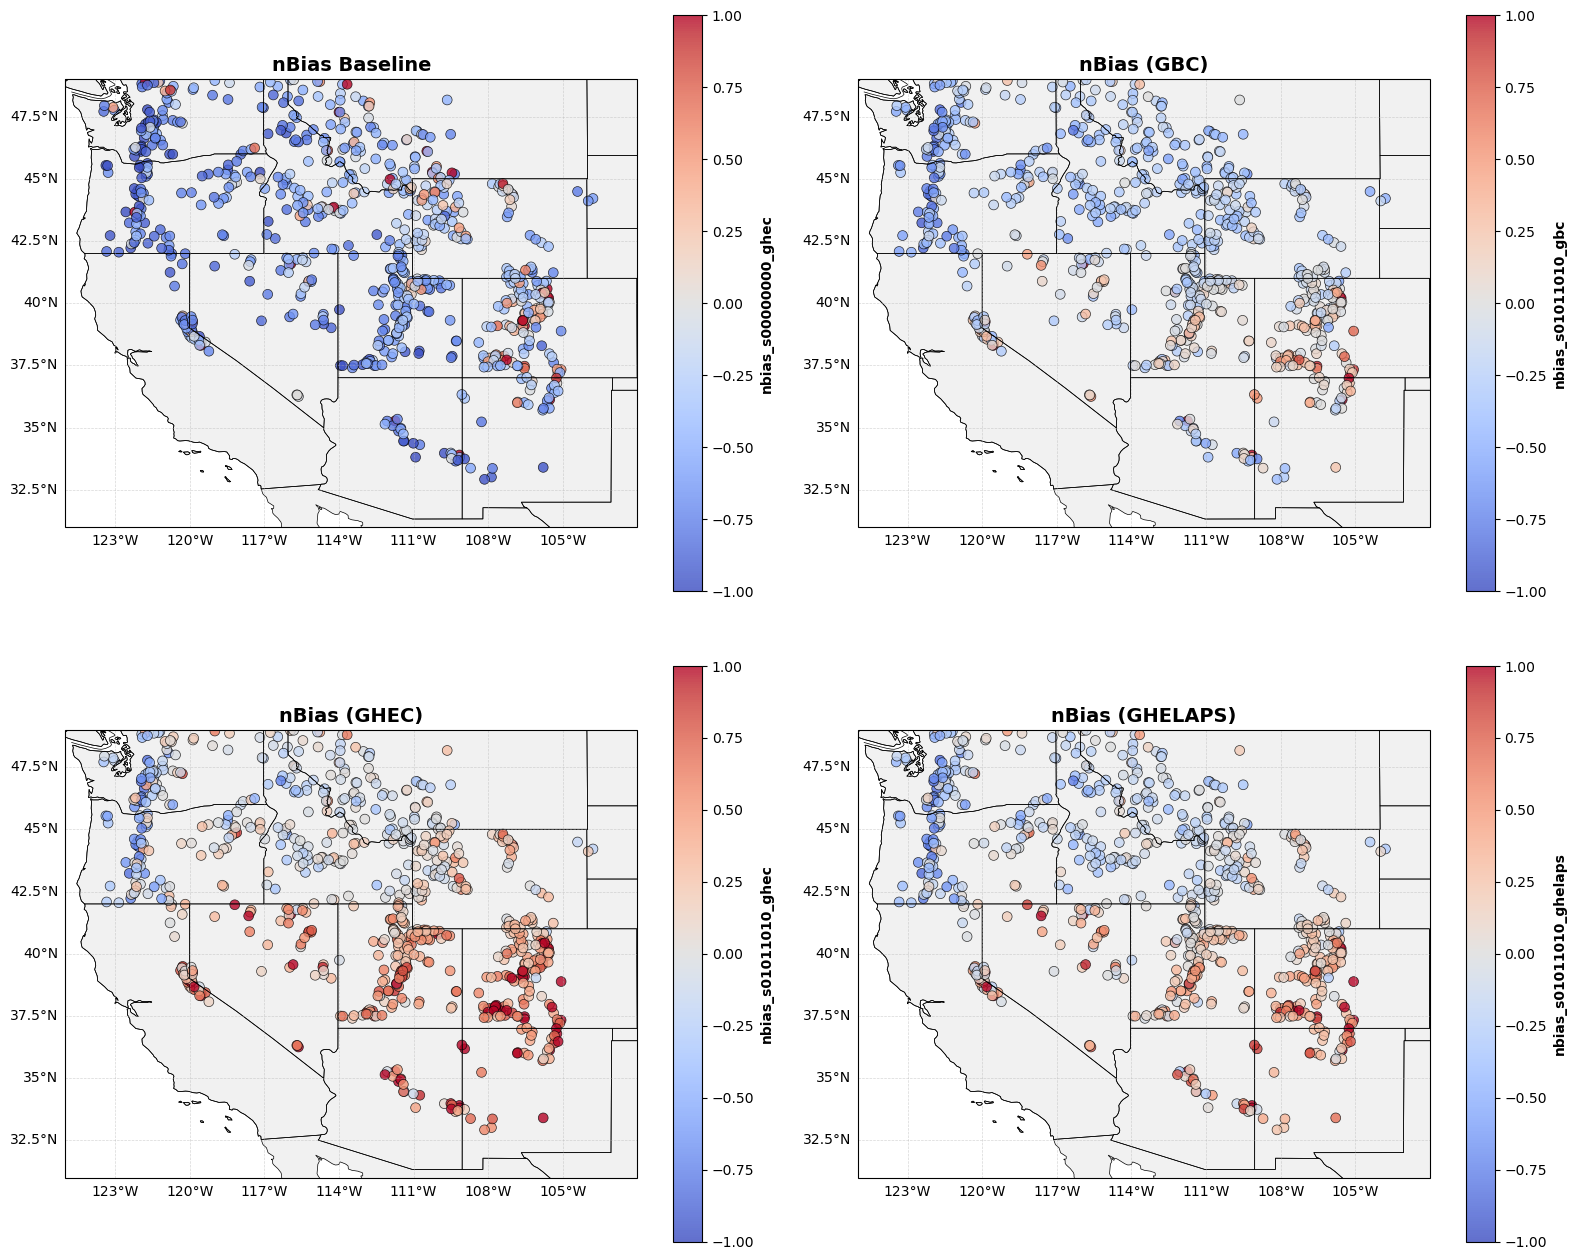

Total data points: 784

Value ranges:
nbias_s00000000_ghec: -1.00 to 3.76
nbias_s01011010_gbc: -0.97 to 2.01
nbias_s01011010_ghec: -0.96 to 37.46
nbias_s01011010_ghelaps: -0.96 to 3.10

Shared colormap range: -1 to 1 (centered on 0)


In [ ]:
# Create figure with 2x2 grid of subplots for normalized bias
fig = plt.figure(figsize=(16, 14))

# Define the columns and titles to plot
columns = ['nbias_s00000000_ghec', 'nbias_s01011010_gbc', 'nbias_s01011010_ghec', 'nbias_s01011010_ghelaps']
titles = ['nBias Baseline', 'nBias (GBC)', 'nBias (GHEC)', 'nBias (GHELAPS)']

# Set color scale limits centered on 0
vmin = -1
vmax = 1

# Create four subplots in 2x2 grid
for pos, (column, title) in enumerate(zip(columns, titles), 1):
    ax = plt.subplot(2, 2, pos, projection=ccrs.PlateCarree())
    
    # Set extent for Western United States
    ax.set_extent([-125, -102, 31, 49], crs=ccrs.PlateCarree())
    
    # Add map features
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor='black')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
    
    # Plot the data points
    scatter = ax.scatter(df['longitude'], df['latitude'],
                         c=df[column],
                         s=50,
                         alpha=0.8,
                         cmap='coolwarm',
                         vmin=vmin,
                         vmax=vmax,
                         transform=ccrs.PlateCarree(),
                         edgecolors='black',
                         linewidth=0.5)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax, orientation='vertical', pad=0.05, shrink=0.8)
    cbar.set_label(column, fontsize=10, fontweight='bold')
    
    # Add gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    
    # Add title
    ax.set_title(title, fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Display basic info about the data
print(f"Total data points: {len(df)}")
print(f"\nValue ranges:")
for column in columns:
    print(f"{column}: {df[column].min():.2f} to {df[column].max():.2f}")
print(f"\nShared colormap range: {vmin} to {vmax} (centered on 0)")

## Bias